# 05 — Machine learning

Do flexible models (trees, forests, boosting, Gaussian process, neural network) predict federal income tax per resident and the social assistance rate better than OLS? And what do they reveal about the shape of the foreign-share relationship?

Models are judged on communes they have not seen, with two cross-validation schemes: random folds, and folds that hold out whole cantons.

Input: `data/processed/communes_2022.csv`. Output: `Results/ml/`.

## 1. Setup, features and cross-validation schemes

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, GroupKFold
sys.path.append("../code")
import helpers

df, tax_sample, sa_sample = helpers.load_model_samples()
OUT = helpers.results_dir("ml")

features = helpers.ml_features

# For each outcome: features X, outcome y, and the canton of each commune (for the canton folds)
outcomes = {
    "Tax (log)":    (features(tax_sample), tax_sample["log_tax"], tax_sample["canton"]),
    "SA rate (pp)": (features(sa_sample), sa_sample["sa_rate"], sa_sample["canton"]),
}

# Two ways of testing on unseen communes
random_cv = KFold(n_splits=5, shuffle=True, random_state=helpers.SEED)
canton_cv = GroupKFold(n_splits=5, shuffle=True, random_state=helpers.SEED)

for label, (X, y, cantons) in outcomes.items():
    print(f"{label}: {X.shape[0]} communes, {X.shape[1]} features, {cantons.nunique()} cantons")
print("Features:", list(X.columns))

# Which cantons are held out together in each canton fold (tax sample)
X, y, cantons = outcomes["Tax (log)"]
canton_folds = pd.DataFrame([
    {"Test cantons": ", ".join(sorted(cantons.iloc[test].unique())), "Test communes": len(test)}
    for train, test in canton_cv.split(X, y, groups=cantons)
], index=[f"Fold {k + 1}" for k in range(5)])
canton_folds.to_csv(OUT / "canton_folds.csv")
canton_folds

Tax (log): 2108 communes, 11 features, 26 cantons
SA rate (pp): 1625 communes, 11 features, 26 cantons
Features: ['foreign_share', 'log_population', 'log_density', 'share_under20', 'share_65plus', 'jobs_per_capita', 'urban_rural_rural', 'urban_rural_urban', 'language_German', 'language_Italian', 'language_Romansh']


,Test cantons,Test communes
Fold 1,"AG, GL, GR, LU, SH, ZG",416
Fold 2,"AI, AR, BS, NW, VS",161
Fold 3,"BE, BL, NE, SG, UR",535
Fold 4,"SO, SZ, TI, VD, ZH",693
Fold 5,"FR, GE, JU, OW, TG",303


## 2. Baselines: the mean, and OLS
Every commune is predicted by a model trained without it (out-of-fold predictions). RMSE: typical prediction error (lower is better). R²: share of the differences between communes predicted correctly (higher is better; 0 = no better than the mean).

In [2]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import cross_val_predict

schemes = {"random folds": random_cv, "canton folds": canton_cv}
predictions = {}     # out-of-fold predictions, kept for later chunks
scores = []          # one row per model, outcome and scheme


def evaluate(name, model, data=None):
    """Predict every commune with `model` trained on the other folds (both outcomes,
    both schemes), then store the predictions and their scores."""
    for label, (X, y, cantons) in (data or outcomes).items():
        for scheme, cv in schemes.items():
            groups = cantons if scheme == "canton folds" else None   # only canton folds need them
            pred = cross_val_predict(model, X, y, cv=cv, groups=groups, n_jobs=-1)
            predictions[(name, label, scheme)] = pred
            scores.append({"model": name, "outcome": label, "scheme": scheme,
                           "RMSE": np.sqrt(mean_squared_error(y, pred)),
                           "R²": r2_score(y, pred)})


def score_table(metric="R²"):
    """Scores so far: one row per model, one column per outcome and scheme."""
    return pd.DataFrame(scores).pivot_table(index="model", columns=["outcome", "scheme"],
                                            values=metric, sort=False).round(3)


evaluate("Mean only (no features)", DummyRegressor(strategy="mean"))
evaluate("OLS", LinearRegression())

display(score_table("R²"))
display(score_table("RMSE"))

outcome                    Tax (log)              SA rate (pp)             
scheme                  random folds canton folds random folds canton folds
model                                                                      
Mean only (no features)       -0.000       -0.105       -0.003       -0.033
OLS                            0.197        0.101        0.220        0.103

outcome                    Tax (log)              SA rate (pp)             
scheme                  random folds canton folds random folds canton folds
model                                                                      
Mean only (no features)        0.660        0.693        1.585        1.608
OLS                            0.591        0.626        1.398        1.499

## 3. A single decision tree
A tree predicts with a sequence of yes/no questions. Its depth is chosen by cross-validation inside each training fold (nested cross-validation), so the test communes never influence it.

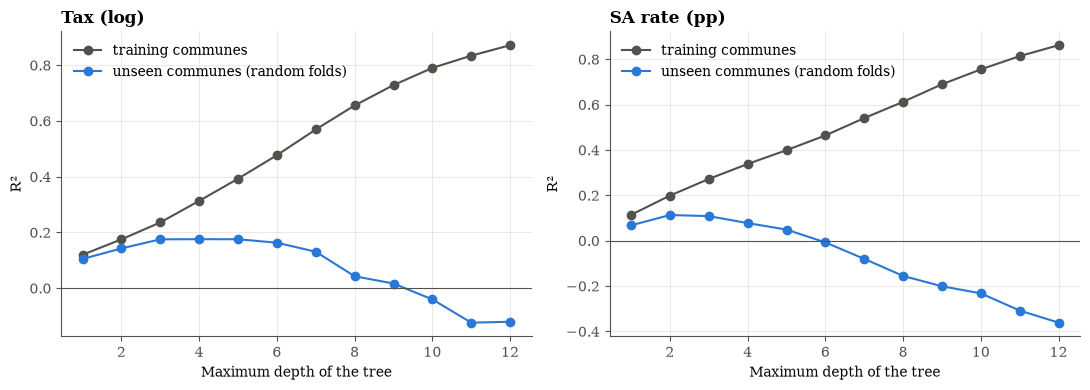

outcome                    Tax (log)              SA rate (pp)             
scheme                  random folds canton folds random folds canton folds
model                                                                      
Mean only (no features)       -0.000       -0.105       -0.003       -0.033
OLS                            0.197        0.101        0.220        0.103
Decision tree                  0.176        0.044        0.123       -0.034

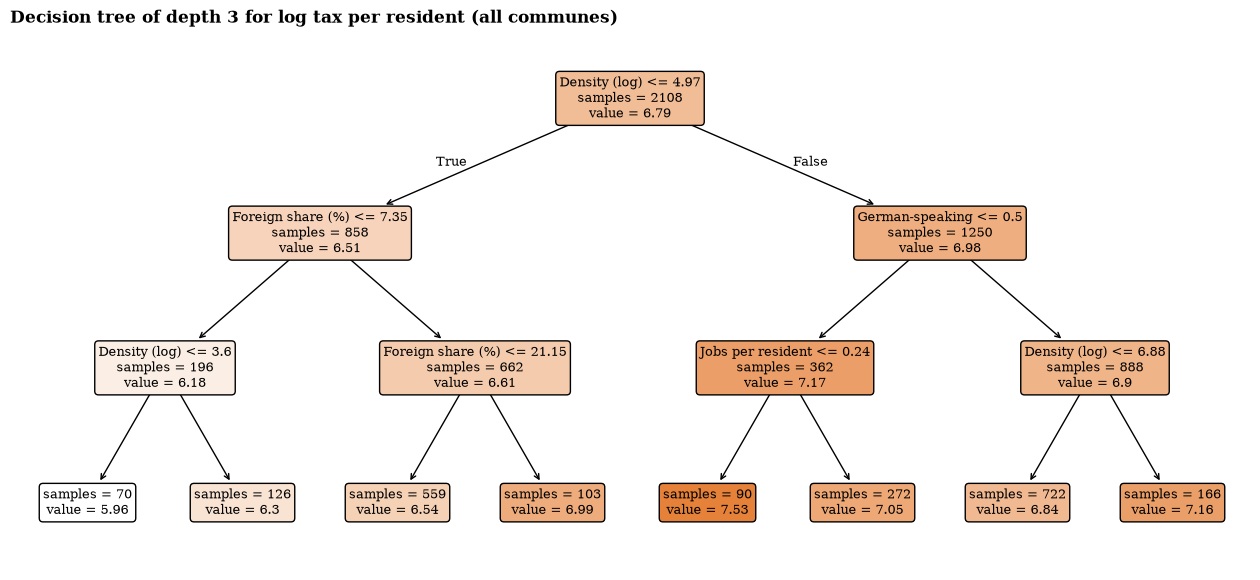

In [3]:
from sklearn.model_selection import GridSearchCV, validation_curve
from sklearn.tree import DecisionTreeRegressor, plot_tree

# Readable feature names, for this and later figures
feature_names = {
    "foreign_share": "Foreign share (%)", "log_population": "Population (log)",
    "log_density": "Density (log)", "share_under20": "Under 20 (%)",
    "share_65plus": "Aged 65+ (%)", "jobs_per_capita": "Jobs per resident",
    "urban_rural_rural": "Rural", "urban_rural_urban": "Urban",
    "language_German": "German-speaking", "language_Italian": "Italian-speaking",
    "language_Romansh": "Romansh-speaking",
}

# (a) How deep should the tree be? Training vs cross-validated R² for depths 1 to 12
depths = range(1, 13)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (label, (X, y, cantons)) in zip(axes, outcomes.items()):
    train_r2, test_r2 = validation_curve(
        DecisionTreeRegressor(random_state=helpers.SEED), X, y,
        param_name="max_depth", param_range=depths, cv=random_cv, scoring="r2", n_jobs=-1)
    ax.plot(depths, train_r2.mean(axis=1), marker="o", color=helpers.INK["secondary"],
            label="training communes")
    ax.plot(depths, test_r2.mean(axis=1), marker="o", color=helpers.COLORS["urban_rural"]["urban"],
            label="unseen communes (random folds)")
    ax.axhline(0, color=helpers.INK["secondary"], linewidth=0.8)
    ax.set_xlabel("Maximum depth of the tree")
    ax.set_ylabel("R²")
    ax.set_title(label)
    ax.legend(frameon=False)
    ax.grid(color=helpers.INK["grid"], linewidth=0.5)
fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_tree_depth.png")
plt.show()

# (b) Score: the depth is chosen inside each training fold (nested cross-validation)
tree = GridSearchCV(DecisionTreeRegressor(random_state=helpers.SEED),
                    param_grid={"max_depth": list(range(1, 11))},
                    cv=KFold(n_splits=5, shuffle=True, random_state=helpers.SEED), scoring="r2")
evaluate("Decision tree", tree)
display(score_table("R²"))

# (c) What a tree looks like: depth 3 on all tax communes, readable in one figure
X, y, cantons = outcomes["Tax (log)"]
small_tree = DecisionTreeRegressor(max_depth=3, random_state=helpers.SEED).fit(X, y)
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(small_tree, feature_names=[feature_names[c] for c in X.columns],
          filled=True, rounded=True, impurity=False, precision=2, fontsize=9, ax=ax)
ax.set_title("Decision tree of depth 3 for log tax per resident (all communes)")
helpers.save_figure(fig, OUT / "fig_tree_tax_depth3.png")
plt.show()

## 4. Random forest and gradient boosting
Many trees combined: a random forest averages 200 different trees; gradient boosting adds small trees one after the other, each correcting the remaining errors. Settings are tuned inside each training fold (nested cross-validation).

In [4]:
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor

inner_cv = KFold(n_splits=5, shuffle=True, random_state=helpers.SEED)

# Random forest: 200 trees, each grown on a bootstrap sample of communes, choosing among a
# random third of the features at each question. Tuned: minimum number of communes per leaf.
forest = GridSearchCV(
    RandomForestRegressor(n_estimators=200, max_features=0.33, random_state=helpers.SEED),
    param_grid={"min_samples_leaf": [1, 5, 20]},
    cv=inner_cv, scoring="r2")

# Gradient boosting: small trees added one after the other, each correcting the errors
# of the previous ones. Tuned: tree size and learning rate (how big each correction is).
boosting = GridSearchCV(
    HistGradientBoostingRegressor(max_iter=300, random_state=helpers.SEED),
    param_grid={"max_depth": [2, 3, 5], "learning_rate": [0.03, 0.1]},
    cv=inner_cv, scoring="r2")

evaluate("Random forest", forest)
evaluate("Gradient boosting", boosting)
display(score_table("R²"))

# Which settings the tuning picks when given all communes (for the paper)
chosen = {}
for label, (X, y, cantons) in outcomes.items():
    for name, search in [("Random forest", forest), ("Gradient boosting", boosting)]:
        chosen[(name, label)] = search.fit(X, y).best_params_
table_tuning = pd.DataFrame(chosen).T
table_tuning.to_csv(OUT / "table_tuning_forest_boosting.csv")
display(table_tuning)

outcome                    Tax (log)              SA rate (pp)             
scheme                  random folds canton folds random folds canton folds
model                                                                      
Mean only (no features)       -0.000       -0.105       -0.003       -0.033
OLS                            0.197        0.101        0.220        0.103
Decision tree                  0.176        0.044        0.123       -0.034
Random forest                  0.345        0.204        0.284        0.136
Gradient boosting              0.327        0.195        0.279        0.119

,,min_samples_leaf,learning_rate,max_depth
Random forest,Tax (log),1.0,NaN,NaN
Gradient boosting,Tax (log),NaN,0.03,5.0
Random forest,SA rate (pp),5.0,NaN,NaN
Gradient boosting,SA rate (pp),NaN,0.03,3.0


## 5. Gaussian process and neural network
Gaussian process: similar communes get similar predictions; similarity (RBF kernel) and noise are learned from the training data by maximum likelihood. Neural network: one or two hidden layers, tuned size and weight penalty, early stopping. Both use standardised features.

In [5]:
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Some neural networks stop before fully converging (early stopping); the warning is expected
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Gaussian process: similar communes (close in the standardised features) get similar
# predictions. Kernel = signal x RBF similarity + noise; its parameters are learned
# from the training communes by maximum likelihood (no grid search needed).
kernel = ConstantKernel(1.0) * RBF(length_scale=1.0) + WhiteKernel(noise_level=1.0)
gaussian_process = make_pipeline(
    StandardScaler(),
    GaussianProcessRegressor(kernel=kernel, normalize_y=True, random_state=helpers.SEED))

# Neural network: one or two hidden layers of neurons; alpha penalises large weights,
# early stopping keeps 10% of the training communes aside and stops when they stop improving.
neural_network = GridSearchCV(
    make_pipeline(StandardScaler(),
                  MLPRegressor(max_iter=2000, early_stopping=True, random_state=helpers.SEED)),
    param_grid={"mlpregressor__hidden_layer_sizes": [(16,), (32, 16)],
                "mlpregressor__alpha": [0.01, 1.0]},
    cv=inner_cv, scoring="r2")

evaluate("Gaussian process", gaussian_process)
evaluate("Neural network", neural_network)
display(score_table("R²"))

outcome                    Tax (log)              SA rate (pp)             
scheme                  random folds canton folds random folds canton folds
model                                                                      
Mean only (no features)       -0.000       -0.105       -0.003       -0.033
OLS                            0.197        0.101        0.220        0.103
Decision tree                  0.176        0.044        0.123       -0.034
Random forest                  0.345        0.204        0.284        0.136
Gradient boosting              0.327        0.195        0.279        0.119
Gaussian process               0.364        0.212        0.333        0.141
Neural network                 0.272        0.025        0.277        0.139

## 6. A fair comparison: OLS with the notebook-04 shapes, and are the gains real?
"OLS + curves" adds foreign share squared and its interactions with urban and rural communes. Each model's gain in R² over OLS is bootstrapped by canton (2,000 draws of 26 cantons with replacement) to get a 95% interval.

outcome                       Tax (log)              SA rate (pp)             
scheme                     random folds canton folds random folds canton folds
model                                                                         
Mean only (no features)          -0.000       -0.105       -0.003       -0.033
OLS                               0.197        0.101        0.220        0.103
Decision tree                     0.176        0.044        0.123       -0.034
Random forest                     0.345        0.204        0.284        0.136
Gradient boosting                 0.327        0.195        0.279        0.119
Gaussian process                  0.364        0.212        0.333        0.141
Neural network                    0.272        0.025        0.277        0.139
OLS + curves (notebook 04)        0.232        0.145        0.232        0.121

gain in R² over OLS  \
outcome      scheme       model                                             
Tax (log)    random folds Decision tree                            -0.021   
                          Random forest                             0.148   
                          Gradient boosting                         0.129   
                          Gaussian process                          0.167   
                          Neural network                            0.074   
                          OLS + curves (notebook 04)                0.035   
             canton folds Decision tree                            -0.057   
                          Random forest                             0.103   
                          Gradient boosting                         0.094   
                          Gaussian process                          0.111   
                          Neural network                           -0.076   
                          OLS + curves (notebook 04)                0.045   
SA rate (pp) random folds Decision tree                            -0.097   
                          Random forest                             0.064   
                          Gradient boosting                         0.059   
                          Gaussian process                          0.113   
                          Neural network                            0.057   
                          OLS + curves (notebook 04)                0.012   
             canton folds Decision tree                            -0.137   
                          Random forest                             0.033   
                          Gradient boosting                         0.016   
                          Gaussian process                          0.038   
                          Neural network                            0.036   
                          OLS + curves (notebook 04)                0.018   

                                                          95% interval  \
outcome      scheme       model                                          
Tax (log)    random folds Decision tree                [-0.114, 0.055]   
                          Random forest                 [0.110, 0.204]   
                          Gradient boosting             [0.085, 0.189]   
                          Gaussian process              [0.115, 0.231]   
                          Neural network               [-0.004, 0.146]   
                          OLS + curves (notebook 04)    [0.009, 0.056]   
             canton folds Decision tree                [-0.127, 0.024]   
                          Random forest                 [0.060, 0.165]   
                          Gradient boosting             [0.038, 0.159]   
                          Gaussian process             [-0.001, 0.212]   
                          Neural network               [-0.466, 0.128]   
                          OLS + curves (notebook 04)    [0.012, 0.074]   
SA rate (pp) random folds Decision tree               [-0.159, -0.021]   
                          Random forest                 [0.028, 0.113]   
                          Gradient boosting             [0.026, 0.113]   
                          Gaussian process              [0.083, 0.164]   
                          Neural network                [0.030, 0.105]   
                          OLS + curves (notebook 04)    [0.002, 0.031]   
             canton folds Decision tree               [-0.287, -0.018]   
                          Random forest                [-0.002, 0.076]   
                          Gradient boosting            [-0.048, 0.089]   
                          Gaussian process             [-0.015, 0.102]   
                          Neural network               [-0.011, 0.081]   
                          OLS + curves (notebook 04)    [0.003, 0.035]   

                                                      share of draws with a gain  
outcome      scheme       model            

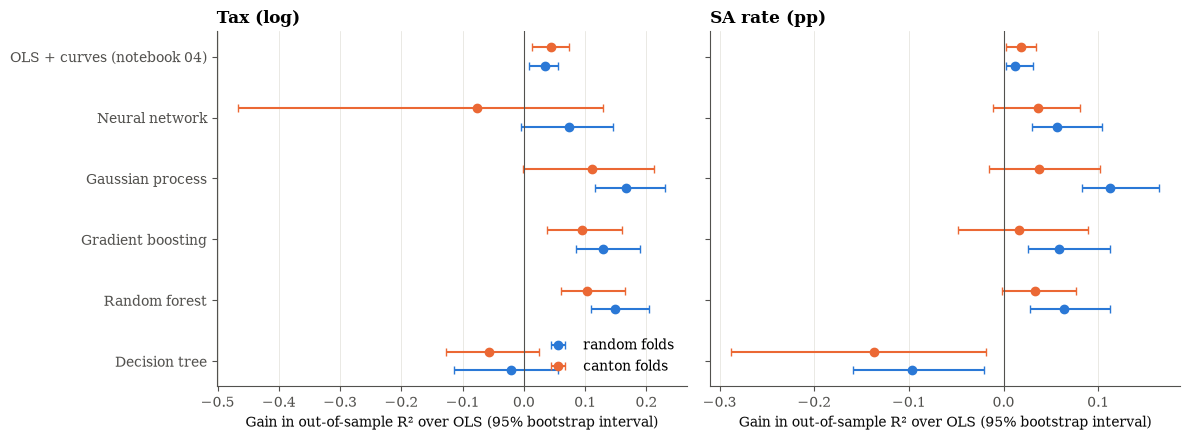

In [6]:
from sklearn.preprocessing import FunctionTransformer


def add_curves(X):
    """Add the shapes found in notebook 04: foreign share squared, and its
    interaction with urban and rural communes."""
    X = X.copy()
    X["foreign_share_sq"] = X["foreign_share"] ** 2
    X["foreign_share_x_urban"] = X["foreign_share"] * X["urban_rural_urban"]
    X["foreign_share_x_rural"] = X["foreign_share"] * X["urban_rural_rural"]
    return X


# (1) A fairer linear rival: OLS that already knows the curve and the urban/rural difference
evaluate("OLS + curves (notebook 04)",
         make_pipeline(FunctionTransformer(add_curves), LinearRegression()))
table_r2 = score_table("R²")
table_r2.to_csv(OUT / "table_r2_all_models.csv")
score_table("RMSE").to_csv(OUT / "table_rmse_all_models.csv")
display(table_r2)

# (2) Is each model's gain over OLS real? Bootstrap by canton: draw 26 cantons with
# replacement 2,000 times and recompute the gain in R² on each draw.
compared = [m for m in table_r2.index if m not in ("Mean only (no features)", "OLS")]
rng = np.random.default_rng(helpers.SEED)
reps = 2000
rows = []
for label, (X, y, cantons) in outcomes.items():
    codes, canton_names = pd.factorize(cantons)
    G = len(canton_names)
    y_values = y.to_numpy()
    counts = rng.multinomial(G, np.ones(G) / G, size=reps)    # times each canton is drawn
    # Sums by canton, so each bootstrap draw is just a weighted sum (fast)
    n_g = np.bincount(codes, minlength=G)
    y_g = np.bincount(codes, weights=y_values, minlength=G)
    y2_g = np.bincount(codes, weights=y_values**2, minlength=G)
    total_variation = counts @ y2_g - (counts @ y_g) ** 2 / (counts @ n_g)
    for scheme in schemes:
        ols_error_g = np.bincount(codes, weights=(y_values - predictions[("OLS", label, scheme)]) ** 2,
                                  minlength=G)
        for model in compared:
            error_g = np.bincount(codes, weights=(y_values - predictions[(model, label, scheme)]) ** 2,
                                  minlength=G)
            gain = (ols_error_g.sum() - error_g.sum()) / ((y_values - y_values.mean()) ** 2).sum()
            gain_draws = counts @ (ols_error_g - error_g) / total_variation
            low, high = np.percentile(gain_draws, [2.5, 97.5])
            rows.append({"outcome": label, "scheme": scheme, "model": model,
                         "gain in R² over OLS": round(gain, 3),
                         "95% interval": f"[{low:.3f}, {high:.3f}]",
                         "share of draws with a gain": round((gain_draws > 0).mean(), 3),
                         "low": low, "high": high})

gains = pd.DataFrame(rows)
gains.drop(columns=["low", "high"]).to_csv(OUT / "table_gain_over_ols_bootstrap.csv", index=False)
display(gains.drop(columns=["low", "high"]).set_index(["outcome", "scheme", "model"]))

# (3) Figure: gain over OLS with its 95% interval
scheme_colors = {"random folds": helpers.COLORS["urban_rural"]["urban"],
                 "canton folds": helpers.COLORS["urban_rural"]["intermediate"]}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, label in zip(axes, outcomes):
    for offset, scheme in zip([-0.15, 0.15], schemes):
        part = gains[(gains["outcome"] == label) & (gains["scheme"] == scheme)].set_index("model").loc[compared]
        ax.errorbar(part["gain in R² over OLS"], np.arange(len(compared)) + offset,
                    xerr=[part["gain in R² over OLS"] - part["low"], part["high"] - part["gain in R² over OLS"]],
                    fmt="o", color=scheme_colors[scheme], capsize=3, label=scheme)
    ax.axvline(0, color=helpers.INK["secondary"], linewidth=0.8)
    ax.set_yticks(range(len(compared)), compared)
    ax.invert_yaxis()
    ax.set_title(label)
    ax.set_xlabel("Gain in out-of-sample R² over OLS (95% bootstrap interval)")
    ax.grid(axis="x", color=helpers.INK["grid"], linewidth=0.5)
axes[0].legend(frameon=False, loc="lower right")
fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_gain_over_ols.png")
plt.show()

## 7. Which features matter? Permutation importance on unseen communes
For each test fold, a forest is trained on the other folds; each feature is then shuffled among the test communes and the drop in R² is measured (10 shuffles, averaged over the 5 folds). Correlated features (density, population, urban) share their importance.

outcome           SA rate (pp)                 Tax (log)             
scheme            canton folds random folds canton folds random folds
feature                                                              
Density (log)            0.056        0.049        0.270        0.290
Foreign share (%)        0.065        0.084        0.148        0.152
Under 20 (%)             0.022        0.013        0.080        0.078
Jobs per resident        0.009        0.022        0.056        0.078
Aged 65+ (%)             0.021        0.027        0.047        0.047
Population (log)         0.070        0.096        0.044        0.052
Urban                   -0.016        0.006        0.010        0.019
German-speaking          0.049        0.068        0.008        0.058
Rural                    0.002       -0.000        0.008        0.018
Italian-speaking         0.002        0.005        0.002        0.002
Romansh-speaking         0.000       -0.000        0.000        0.000

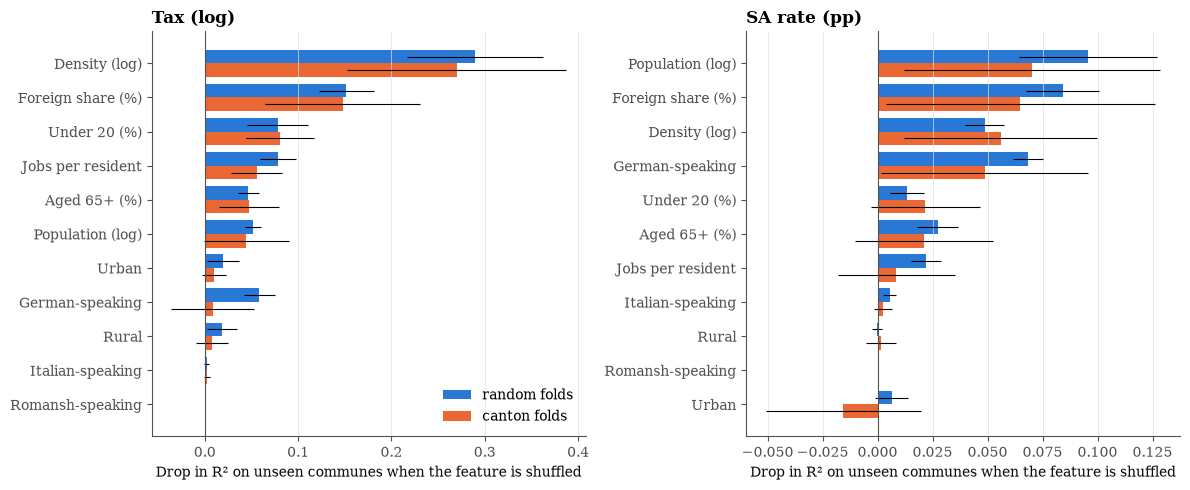

In [7]:
from sklearn.inspection import permutation_importance

# For each test fold: train a forest on the other folds (with the settings tuned in
# section 4), then shuffle one feature at a time in the test fold and measure how much
# the R² on those unseen communes drops. A big drop = the forest relies on that feature.
rows = []
for label, (X, y, cantons) in outcomes.items():
    leaf = chosen[("Random forest", label)]["min_samples_leaf"]
    for scheme, cv in schemes.items():
        groups = cantons if scheme == "canton folds" else None
        for fold, (train, test) in enumerate(cv.split(X, y, groups=groups)):
            forest_fold = RandomForestRegressor(n_estimators=200, max_features=0.33,
                                                min_samples_leaf=leaf, random_state=helpers.SEED,
                                                n_jobs=-1).fit(X.iloc[train], y.iloc[train])
            result = permutation_importance(forest_fold, X.iloc[test], y.iloc[test], scoring="r2",
                                            n_repeats=10, random_state=helpers.SEED, n_jobs=-1)
            for feature, drop in zip(X.columns, result.importances_mean):
                rows.append({"outcome": label, "scheme": scheme, "fold": fold,
                             "feature": feature_names[feature], "drop in R²": drop})

importance = pd.DataFrame(rows)
# Average over the 5 test folds (and keep the spread across folds for the error bars)
summary = importance.groupby(["outcome", "scheme", "feature"])["drop in R²"].agg(["mean", "std"])
table_importance = summary["mean"].unstack(["outcome", "scheme"]).sort_values(
    ("Tax (log)", "canton folds"), ascending=False).round(3)
table_importance.to_csv(OUT / "table_permutation_importance.csv")
display(table_importance)

# Figure: one panel per outcome, features sorted by importance (canton folds)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, label in zip(axes, outcomes):
    order = summary.loc[(label, "canton folds")]["mean"].sort_values().index
    for offset, scheme in zip([0.2, -0.2], schemes):
        part = summary.loc[(label, scheme)].loc[order]
        ax.barh(np.arange(len(order)) + offset, part["mean"], height=0.4, xerr=part["std"],
                color=scheme_colors[scheme], label=scheme, error_kw={"linewidth": 0.8})
    ax.set_yticks(range(len(order)), order)
    ax.axvline(0, color=helpers.INK["secondary"], linewidth=0.8)
    ax.set_title(label)
    ax.set_xlabel("Drop in R² on unseen communes when the feature is shuffled")
    ax.grid(axis="x", color=helpers.INK["grid"], linewidth=0.5)
axes[0].legend(frameon=False, loc="lower right")
fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_permutation_importance.png")
plt.show()

## 8. The shape of the foreign-share effect: partial dependence
For each value of foreign share, every commune's foreign share is set to that value (other features unchanged) and the predictions are averaged. Thin lines: 100 individual communes (ICE). Bottom row: the forest's curve within each commune type. Ticks: deciles of foreign share.

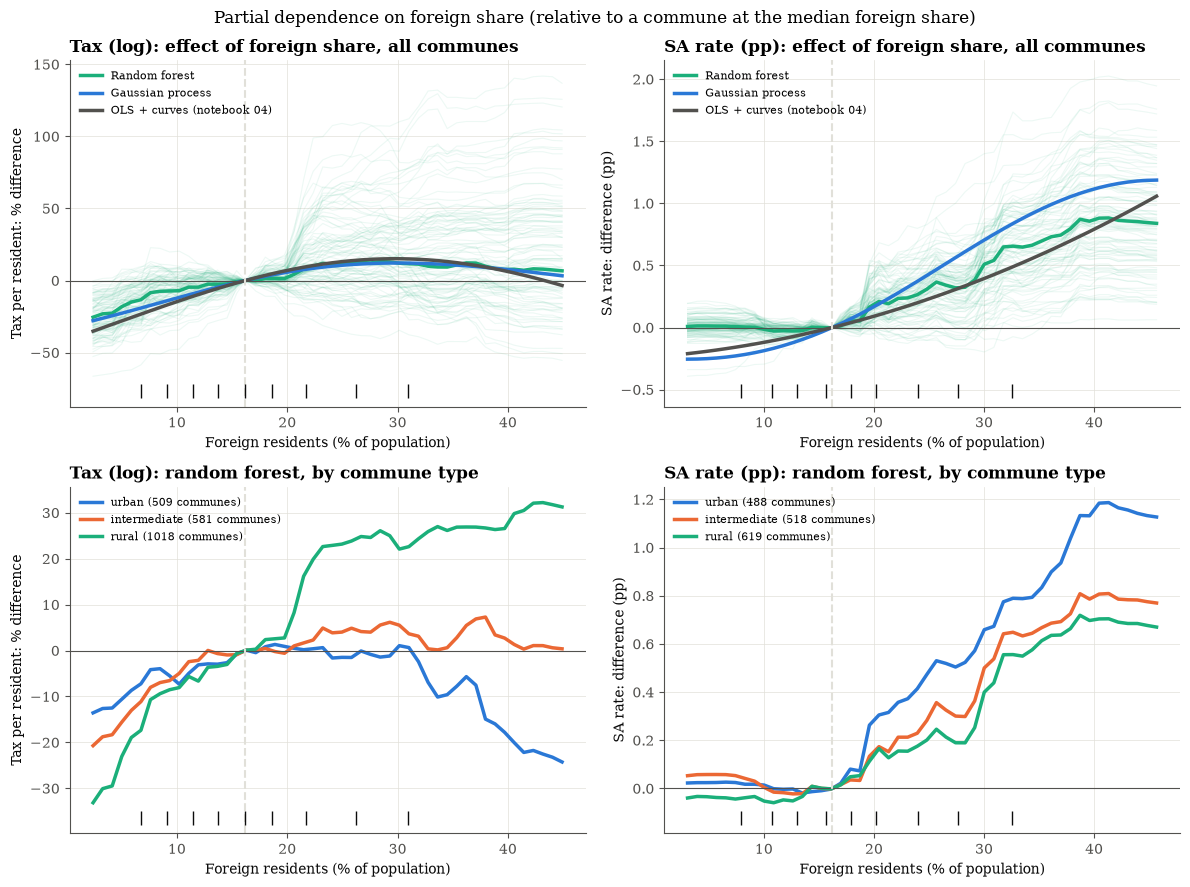

In [8]:
from sklearn.base import clone
from sklearn.inspection import partial_dependence

# Fit three models on all communes: the two best flexible models, and OLS with the
# notebook-04 shapes (for comparison). Partial dependence describes these fitted models.
fitted = {}
for label, (X, y, cantons) in outcomes.items():
    leaf = chosen[("Random forest", label)]["min_samples_leaf"]
    fitted[(label, "Random forest")] = RandomForestRegressor(
        n_estimators=200, max_features=0.33, min_samples_leaf=leaf,
        random_state=helpers.SEED, n_jobs=-1).fit(X, y)
    fitted[(label, "Gaussian process")] = clone(gaussian_process).fit(X, y)
    fitted[(label, "OLS + curves (notebook 04)")] = make_pipeline(
        FunctionTransformer(add_curves), LinearRegression()).fit(X, y)

model_colors = {"Random forest": helpers.COLORS["urban_rural"]["rural"],
                "Gaussian process": helpers.COLORS["urban_rural"]["urban"],
                "OLS + curves (notebook 04)": helpers.INK["secondary"]}
median_fs = df["foreign_share"].median()


def relative(curve, grid, label):
    """Curve relative to its value at the median foreign share: % for tax, pp for SA."""
    shifted = curve - np.interp(median_fs, grid, curve)
    return 100 * (np.exp(shifted) - 1) if label.startswith("Tax") else shifted


fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for col, (label, (X, y, cantons)) in enumerate(outcomes.items()):
    ylabel = "Tax per resident: % difference" if label.startswith("Tax") else "SA rate: difference (pp)"

    # Row 1: average effect of foreign share, three models, plus 100 individual communes (forest)
    ax = axes[0, col]
    for name, color in model_colors.items():
        pdp = partial_dependence(fitted[(label, name)], X, ["foreign_share"], kind="both",
                                 grid_resolution=50, percentiles=(0.01, 0.99))
        grid = pdp["grid_values"][0]
        if name == "Random forest":
            sample = np.random.default_rng(helpers.SEED).choice(len(X), 100, replace=False)
            for curve in pdp["individual"][0][sample]:
                ax.plot(grid, relative(curve, grid, label), color=color, alpha=0.08, linewidth=0.8)
        ax.plot(grid, relative(pdp["average"][0], grid, label), color=color, linewidth=2.5, label=name)
    ax.set_title(f"{label}: effect of foreign share, all communes")

    # Row 2: the forest's average effect within each commune type (does the shape differ?)
    ax2 = axes[1, col]
    pdp = partial_dependence(fitted[(label, "Random forest")], X, ["foreign_share"], kind="individual",
                             grid_resolution=50, percentiles=(0.01, 0.99))
    grid = pdp["grid_values"][0]
    commune_type = (tax_sample if label.startswith("Tax") else sa_sample)["urban_rural"].to_numpy()
    for t in helpers.ORDER["urban_rural"]:
        curve = pdp["individual"][0][commune_type == t].mean(axis=0)
        ax2.plot(grid, relative(curve, grid, label), color=helpers.COLORS["urban_rural"][t],
                 linewidth=2.5, label=f"{t} ({(commune_type == t).sum()} communes)")
    ax2.set_title(f"{label}: random forest, by commune type")

    for a in (ax, ax2):
        a.axhline(0, color=helpers.INK["secondary"], linewidth=0.8)
        a.axvline(median_fs, color=helpers.INK["grid"], linestyle="--")
        # where the communes are: one tick per decile of foreign share
        a.plot(np.percentile(X["foreign_share"], np.arange(10, 100, 10)),
               np.full(9, a.get_ylim()[0]), "|", color=helpers.INK["primary"], markersize=10)
        a.set_xlabel(helpers.LABELS["foreign_share"])
        a.set_ylabel(ylabel)
        a.legend(frameon=False, fontsize=8)
        a.grid(color=helpers.INK["grid"], linewidth=0.5)

fig.suptitle("Partial dependence on foreign share (relative to a commune at the median foreign share)")
fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_partial_dependence_foreign_share.png")
plt.show()

## 9. Does the commune's location help? Coordinates as features
The forest also gets each commune's east and north coordinates (km) and its distance to the national border. Does it predict better, and does the foreign-share curve change once location is known?

outcome                     Tax (log)              SA rate (pp)             
scheme                   random folds canton folds random folds canton folds
model                                                                       
OLS                             0.197        0.101        0.220        0.103
Random forest                   0.345        0.204        0.284        0.136
Random forest + location        0.560        0.376        0.469        0.198

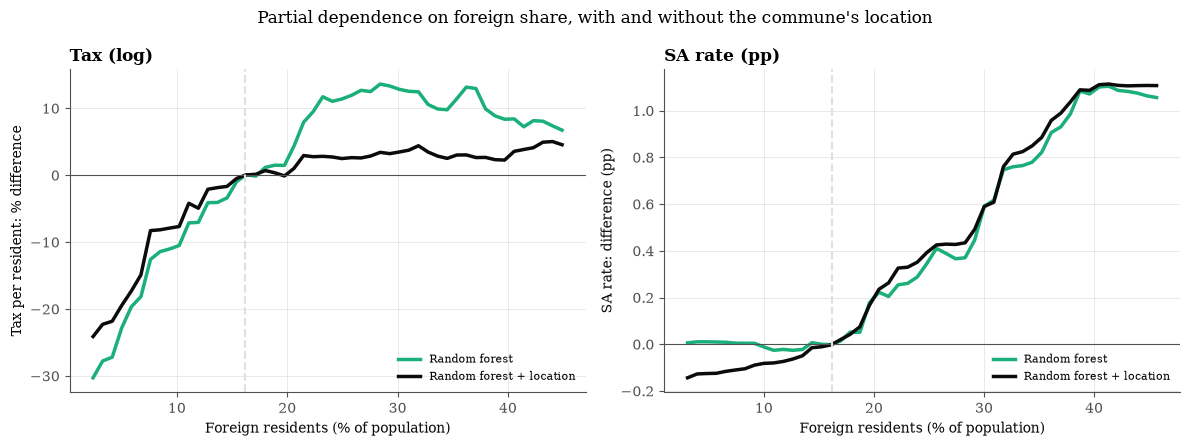

In [9]:
def features_with_location(data):
    """The 11 features plus where the commune is: east and north coordinates (km)
    and distance to the national border (km)."""
    location = pd.DataFrame({"east_km": data["x_lv95"] / 1000, "north_km": data["y_lv95"] / 1000,
                             "border_km": data["border_km"]}, index=data.index)
    return pd.concat([features(data), location], axis=1)


outcomes_location = {
    "Tax (log)":    (features_with_location(tax_sample), tax_sample["log_tax"], tax_sample["canton"]),
    "SA rate (pp)": (features_with_location(sa_sample), sa_sample["sa_rate"], sa_sample["canton"]),
}

# (1) Does knowing the location help the forest predict unseen communes?
evaluate("Random forest + location", forest, data=outcomes_location)
table_r2 = score_table("R²")
table_r2.to_csv(OUT / "table_r2_all_models.csv")
display(table_r2.loc[["OLS", "Random forest", "Random forest + location"]])

# (2) Does the foreign-share curve change once location is known?
feature_names.update({"east_km": "East (km)", "north_km": "North (km)", "border_km": "Distance to border (km)"})
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (label, (X_loc, y, cantons)) in zip(axes, outcomes_location.items()):
    leaf = chosen[("Random forest", label)]["min_samples_leaf"]
    forest_location = RandomForestRegressor(n_estimators=200, max_features=0.33, min_samples_leaf=leaf,
                                            random_state=helpers.SEED, n_jobs=-1).fit(X_loc, y)
    X = outcomes[label][0]
    for name, model, data, color in [
            ("Random forest", fitted[(label, "Random forest")], X, model_colors["Random forest"]),
            ("Random forest + location", forest_location, X_loc, helpers.INK["primary"])]:
        pdp = partial_dependence(model, data, ["foreign_share"], kind="average",
                                 grid_resolution=50, percentiles=(0.01, 0.99))
        grid = pdp["grid_values"][0]
        ax.plot(grid, relative(pdp["average"][0], grid, label), color=color, linewidth=2.5, label=name)
    ax.axhline(0, color=helpers.INK["secondary"], linewidth=0.8)
    ax.axvline(median_fs, color=helpers.INK["grid"], linestyle="--")
    ax.set_xlabel(helpers.LABELS["foreign_share"])
    ax.set_ylabel("Tax per resident: % difference" if label.startswith("Tax") else "SA rate: difference (pp)")
    ax.set_title(label)
    ax.legend(frameon=False, fontsize=8)
    ax.grid(color=helpers.INK["grid"], linewidth=0.5)
fig.suptitle("Partial dependence on foreign share, with and without the commune's location")
fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_partial_dependence_with_location.png")
plt.show()

## 10. Double machine learning: the foreign-share coefficient with flexible controls
Partially linear model (Chernozhukov et al. 2018): the outcome and the foreign share are each predicted from the M4 controls (including canton dummies) with machine learning, cross-fitted over 5 folds; the coefficient is the slope of the outcome residuals on the foreign-share residuals. Standard errors clustered by canton.

,Tax (log),SA rate (pp)
No controls,0.0199*** (0.0054),0.0557*** (0.0102)
"OLS, linear controls (= M4)",0.0002 (0.0054),0.0515*** (0.0102)
"DML, random forest",0.0028 (0.0047),0.0482*** (0.0115)
"DML, gradient boosting",0.0032 (0.0048),0.0510*** (0.0117)
"DML, random forest + location",-0.0021 (0.0049),0.0578*** (0.0147)


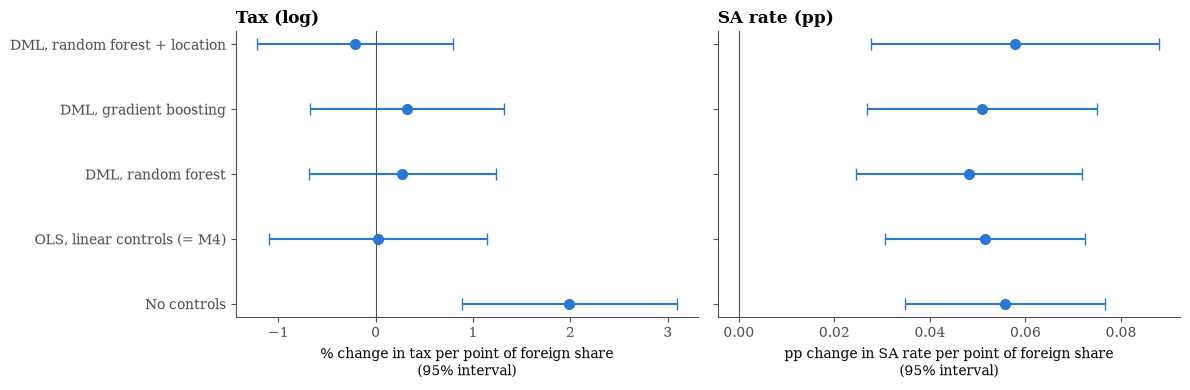

In [10]:
from scipy import stats


def dml_controls(data, location=False):
    """Controls of model M4 (everything except foreign share, with canton dummies),
    optionally with the commune's location."""
    parts = [features(data).drop(columns="foreign_share"),
             pd.get_dummies(data["canton"], prefix="canton", drop_first=True, dtype=float)]
    if location:
        parts.append(features_with_location(data)[["east_km", "north_km", "border_km"]])
    return pd.concat(parts, axis=1)


def residuals(model, X, target, cross_fit):
    """What is left of `target` after predicting it from the controls X.
    Cross-fitted: each commune is predicted by a model trained on the other folds."""
    if model is None:                                   # no controls: just remove the mean
        return target - target.mean()
    if cross_fit:
        folds = KFold(n_splits=5, shuffle=True, random_state=helpers.SEED)
        return target - cross_val_predict(model, X, target, cv=folds, n_jobs=-1)
    return target - model.fit(X, target).predict(X)


def effect_from_residuals(y_res, d_res, cantons):
    """Regress the outcome residuals on the foreign-share residuals (Frisch-Waugh-Lovell);
    standard error clustered by canton, p-value from a t-distribution with G-1 degrees of freedom."""
    theta = (d_res @ y_res) / (d_res @ d_res)
    scores = pd.Series(d_res * (y_res - theta * d_res)).groupby(cantons.to_numpy()).sum()
    G = len(scores)
    se = np.sqrt(G / (G - 1) * (scores**2).sum()) / (d_res @ d_res)
    p = 2 * stats.t.sf(abs(theta / se), df=G - 1)
    return theta, se, p


forest_nuisance = RandomForestRegressor(n_estimators=200, max_features=0.33, min_samples_leaf=5,
                                        random_state=helpers.SEED)
boosting_nuisance = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.03, max_depth=3,
                                                  random_state=helpers.SEED)
methods = {   # name: (model for the controls, cross-fitted?, with location?)
    "No controls":                       (None, False, False),
    "OLS, linear controls (= M4)":       (LinearRegression(), False, False),
    "DML, random forest":                (forest_nuisance, True, False),
    "DML, gradient boosting":            (boosting_nuisance, True, False),
    "DML, random forest + location":     (forest_nuisance, True, True),
}

rows, results = {}, []
for label, sample, outcome in [("Tax (log)", tax_sample, "log_tax"),
                               ("SA rate (pp)", sa_sample, "sa_rate")]:
    y = sample[outcome].to_numpy()
    d = sample["foreign_share"].to_numpy()
    for name, (model, cross_fit, location) in methods.items():
        X = dml_controls(sample, location)
        y_res = residuals(model, X, pd.Series(y), cross_fit).to_numpy()
        d_res = residuals(model, X, pd.Series(d), cross_fit).to_numpy()
        theta, se, p = effect_from_residuals(y_res, d_res, sample["canton"])
        rows.setdefault(name, {})[label] = f"{theta:.4f}{helpers.stars(p)} ({se:.4f})"
        results.append({"outcome": label, "method": name, "coef": theta, "se": se, "p": p})

table_dml = pd.DataFrame(rows).T
table_dml.to_csv(OUT / "table_double_machine_learning.csv")
display(table_dml)

# Figure: the foreign-share coefficient by method, with 95% intervals
results = pd.DataFrame(results)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (label, scale, unit) in zip(axes, [("Tax (log)", 100, "% change in tax"),
                                           ("SA rate (pp)", 1, "pp change in SA rate")]):
    part = results[results["outcome"] == label].set_index("method").loc[list(methods)]
    t_crit = stats.t.ppf(0.975, df=25)
    ax.errorbar(part["coef"] * scale, range(len(part)), xerr=t_crit * part["se"] * scale,
                fmt="o", color=helpers.COLORS["urban_rural"]["urban"], capsize=4, markersize=7)
    ax.axvline(0, color=helpers.INK["secondary"], linewidth=0.8)
    ax.set_yticks(range(len(part)), part.index)
    ax.invert_yaxis()
    ax.set_title(label)
    ax.set_xlabel(f"{unit} per point of foreign share\n(95% interval)")
fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_double_machine_learning.png")
plt.show()

## 11. LaTeX versions of the main tables

In [11]:
# LaTeX versions of the main tables, for the paper (Overleaf)
paper_tables = {
    "table_canton_folds": canton_folds,
    "table_r2_all_models": score_table("R²"),
    "table_rmse_all_models": score_table("RMSE"),
    "table_tuning_forest_boosting": table_tuning,
    "table_gain_over_ols_bootstrap": gains.drop(columns=["low", "high"]).set_index(["outcome", "scheme", "model"]),
    "table_permutation_importance": table_importance,
    "table_double_machine_learning": table_dml,
}
for name, table in paper_tables.items():
    latex = table.to_latex(escape=True, na_rep="", float_format="%.3f")
    _ = (OUT / f"{name}.tex").write_text(latex, encoding="utf-8")
print("Saved:", len(paper_tables), "tables")

Saved: 7 tables


## 12. Summary

**Prediction on unseen communes (out-of-sample R²):**

| Model | Tax, random folds | Tax, canton folds | SA, random folds | SA, canton folds |
|---|---|---|---|---|
| OLS | 0.197 | 0.101 | 0.220 | 0.103 |
| OLS + curves (notebook 04) | 0.232 | 0.145 | 0.232 | 0.121 |
| Random forest | 0.345 | 0.204 | 0.284 | 0.136 |
| Gradient boosting | 0.327 | 0.195 | 0.279 | 0.119 |
| Gaussian process | 0.364 | 0.212 | 0.333 | 0.141 |
| Neural network | 0.272 | 0.025 | 0.277 | 0.139 |
| Random forest + location | 0.560 | 0.376 | 0.469 | 0.198 |

| Result | Evidence |
|---|---|
| Flexible models predict **tax** clearly better than OLS, also in cantons they have never seen | canton bootstrap: forest +0.10 R² over OLS, 95% interval [0.06, 0.17] |
| For **social assistance**, flexible models help only within known regions; across cantons they do not reliably beat OLS | all canton-fold intervals include zero |
| The notebook-04 shapes (squared term, urban/rural interaction) explain part of the tax gain, not all of it | OLS + curves: +0.035 to +0.045 R² |
| Foreign share is the **second most important** feature for both outcomes (after density for tax, population for SA) | permutation importance on held-out communes |
| Tax rises with foreign share up to about 25–30% and then levels off; it rises steeply in rural communes (around 20%) and falls in urban communes above about 30% | partial dependence (forest, Gaussian process) |
| Social assistance is flat below the median foreign share and then rises, by about +1.1 pp at 40%; steepest in urban communes | partial dependence |
| Location (coordinates) improves prediction strongly; it flattens the tax curve but leaves the social-assistance curve unchanged | forest + location; partial dependence with and without location |
| With flexible controls, the average foreign-share coefficient is ≈ 0 for tax and ≈ +0.05 pp per point for social assistance, as in OLS (M4) | double machine learning with forest and boosting, with and without location |

Flexible models confirm the regression results of notebook 04 and add detail: the tax association is non-linear, depends on the type of commune and is largely geographic, while the social-assistance association is close to linear and robust to flexible controls and to location. A single tree is weaker than OLS, and the neural network is unreliable across cantons. The neural network's canton-fold result, the thin data above about 30% foreign share, and the partial-dependence curves far from observed combinations of features should be read with caution. All results are associations between communes, not causal effects.